# EDA na Prática — Bank Marketing (UCI)

Aplicação do roteiro da aula prática de EDA (Aulas 9, 10 e 11) ao dataset **Bank Marketing** do UCI Machine Learning Repository.

**Contexto do dataset:** registros de campanhas de *marketing direto por telefone* de um banco português, entre maio de 2008 e novembro de 2010. Cada linha é um cliente contatado; o alvo `y` indica se o cliente **assinou um depósito a prazo** (`yes`/`no`). Fonte: Moro, Laureano & Cortez (2011), *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology*.

Seguimos o mesmo ciclo **iterativo** da aula: estrutura → estatística descritiva "antes" → tratamento de ausentes e outliers → estatística descritiva "depois" → análise relacional (bivariada e multivariada).

## Setup de Bibliotecas e Dados

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra classe de referência ("Não assinou")
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse ("Assinou")
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

SEED = 42  # amostras reprodutíveis (testes e gráficos com muitos pontos)

# Funciona rodando o notebook a partir da raiz do projeto ou de notebooks/
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

## Carregando o Dataset

Usamos o arquivo `bank-full.csv` (todas as 45.211 linhas, ordenadas por data), baixado do UCI (`bank+marketing.zip` → `bank.zip`) e salvo em `data/raw/`. O CSV usa `;` como separador.

In [2]:
# Bank Marketing (UCI Machine Learning Repository, id=222) — bank-full.csv
df = pd.read_csv(RAIZ / "data" / "raw" / "bank-full.csv", sep=";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o dataset tem 16 variáveis preditoras (dados do cliente, do último contato da campanha atual e de campanhas anteriores) mais o alvo `y`. Por ser um registro operacional de *call center* de um banco ao longo de ~2,5 anos, esperamos **dezenas de milhares** de linhas — bem mais que um dataset clínico.

| Grupo | Variáveis |
|---|---|
| Cliente | `age`, `job`, `marital`, `education`, `default` (inadimplente?), `balance` (saldo médio anual, €), `housing` (financ. imobiliário?), `loan` (empréstimo pessoal?) |
| Último contato | `contact` (tipo), `day`, `month`, `duration` (duração em segundos) |
| Histórico | `campaign` (nº de contatos nesta campanha), `pdays` (dias desde o último contato anterior; `-1` = nunca contatado), `previous` (nº de contatos antes desta campanha), `poutcome` (resultado da campanha anterior) |
| Alvo | `y` — assinou o depósito a prazo? |

### Dimensão e Tipos de Dados

In [3]:
df.shape

(45211, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


**Observações estruturais:**
- 45.211 linhas e 17 colunas: 7 numéricas inteiras e 10 categóricas (`object`).
- `df.info()` não mostra nenhum nulo, mas isso **não** quer dizer que não há dados ausentes — veremos na Seção 2 que eles estão codificados como a string `"unknown"`.
- `pdays` tem mínimo `-1`: é um **valor sentinela** ("nunca contatado"), não um número de dias. Tratar `-1` como número distorce média, mediana e correlações.
- `balance` tem valores negativos (mínimo −8.019 €) — saldo devedor, plausível num banco.

### Duplicadas

In [6]:
df.duplicated().sum()

np.int64(0)

Nenhuma linha duplicada. Como o dataset não tem um identificador de cliente, também não é possível checar se a mesma pessoa aparece mais de uma vez.

### Renomeando o atributo alvo para facilitar a interpretação

O alvo original `y` vem como `yes`/`no`. Vamos criar a coluna `assinou_deposito` com rótulos em português, já na convenção de cor que vamos usar ao longo do notebook (rosa = "Não assinou", roxo = "Assinou").

In [7]:
df["assinou_deposito"] = np.where(df["y"] == "yes", "Assinou", "Não assinou")
print(df["assinou_deposito"].value_counts())
df.drop(columns=["y"], inplace=True)
df.head()

assinou_deposito
Não assinou    39922
Assinou         5289
Name: count, dtype: int64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,assinou_deposito
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,Não assinou
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,Não assinou
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,Não assinou
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,Não assinou
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,Não assinou


## 2. Dados Faltantes

In [8]:
df.isna().sum()

age                 0
job                 0
marital             0
education           0
default             0
balance             0
housing             0
loan                0
contact             0
day                 0
month               0
duration            0
campaign            0
pdays               0
previous            0
poutcome            0
assinou_deposito    0
dtype: int64

**Discussão:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: pelo `isna()`, nenhuma. Mas a documentação do dataset avisa que as categóricas usam o rótulo `"unknown"` para informação desconhecida. Esse é um caso clássico de **ausente disfarçado**: precisamos convertê-lo para `NaN` antes de contar. Além disso, `pdays = -1` também é uma forma de ausência ("não se aplica").

In [9]:
contagem_unknown = (df == "unknown").sum()
contagem_unknown = contagem_unknown[contagem_unknown > 0]
pd.DataFrame({"n_unknown": contagem_unknown,
              "pct": (contagem_unknown / len(df) * 100).round(2)})

,n_unknown,pct
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


In [10]:
# Convertendo o "unknown" em NaN de verdade, para usar as ferramentas de ausentes do pandas
df = df.replace("unknown", np.nan)
df.isna().sum()

age                     0
job                   288
marital                 0
education            1857
default                 0
balance                 0
housing                 0
loan                    0
contact             13020
day                     0
month                   0
duration                0
campaign                0
pdays                   0
previous                0
poutcome            36959
assinou_deposito        0
dtype: int64

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

Quatro colunas têm ausentes, mas com volumes e naturezas bem diferentes:

* `job` (288, 0,6%) e `education` (1.857, 4,1%) — dados cadastrais do cliente.
* `contact` (13.020, 28,8%) — tipo de telefone usado no último contato (celular ou fixo).
* `poutcome` (36.959, 81,7%) — resultado da campanha **anterior**.

*Como os dados foram coletados:*
- São registros do sistema de *call center* de um único banco, em ordem cronológica (mai/2008 a nov/2010). Os dados cadastrais vêm da base de clientes; os dados de contato vêm do sistema de discagem.

*Qual a natureza da fonte de dados:*
- `poutcome` só faz sentido para quem participou de uma campanha anterior. Para quem nunca foi contatado (`pdays = -1`), "unknown" é **estruturalmente ausente** ("não se aplica"), e não um dado perdido.
- `contact` depende do sistema de registro: se o banco começou a registrar o tipo de telefone só a partir de certa data, a ausência vai depender do **período**, não do cliente.

**As ausências ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático.

In [11]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['job', 'education', 'contact', 'poutcome']
job            288
education     1857
contact      13020
poutcome     36959
dtype: int64


Aqui temos 4 colunas e volumes grandes (milhares de linhas), então — como a nota da aula sugeria — uma **correlação entre os indicadores de ausência** passa a fazer sentido, além da contagem bruta.

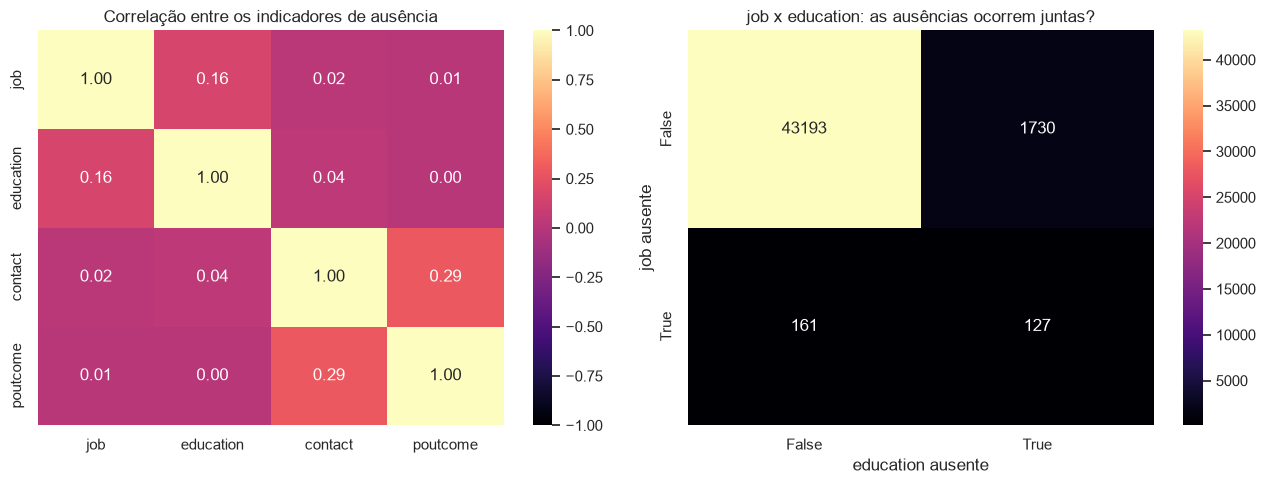

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(df[cols_com_ausentes].isna().corr(), annot=True, fmt=".2f",
            cmap="magma", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlação entre os indicadores de ausência")

tabela_contingencia = pd.crosstab(df["job"].isna(), df["education"].isna(),
                                  rownames=["job ausente"], colnames=["education ausente"])
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=axes[1])
axes[1].set_title("job x education: as ausências ocorrem juntas?")

plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR)?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionado à própria feature

*Resposta*: só 127 linhas têm `job` **e** `education` ausentes, e a correlação entre os indicadores é fraca; as quatro colunas não "somem juntas". Para entender cada mecanismo, vamos cruzar a ausência com outras variáveis.

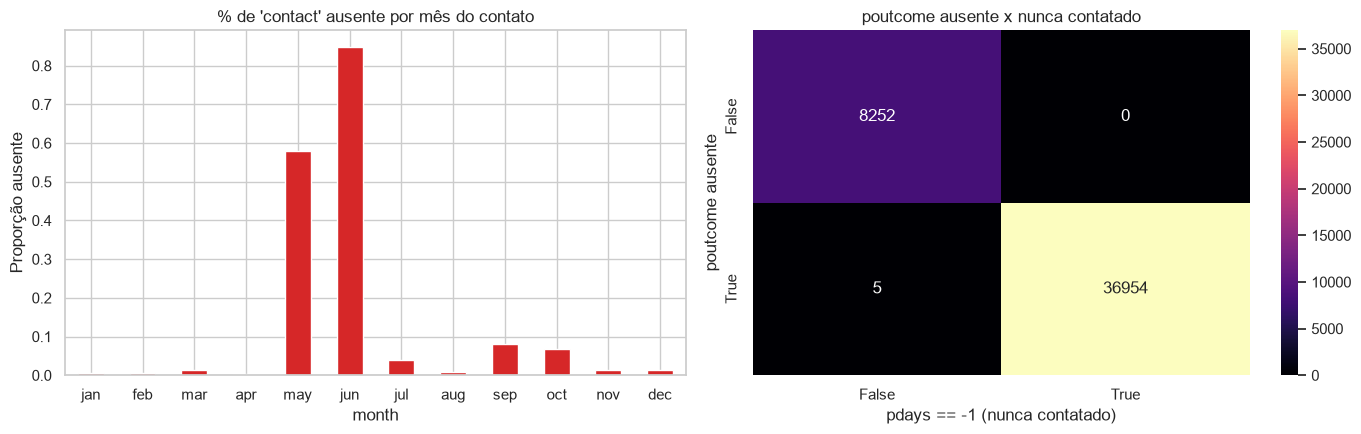

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# contact ausente x mês do contato
ordem_meses = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
pct_contact_ausente = df.groupby("month")["contact"].apply(lambda s: s.isna().mean()).reindex(ordem_meses)
pct_contact_ausente.plot(kind="bar", color=COR_ALERTA, ax=axes[0])
axes[0].set_title("% de 'contact' ausente por mês do contato")
axes[0].set_ylabel("Proporção ausente")
axes[0].tick_params(axis="x", rotation=0)

# poutcome ausente x nunca contatado antes (pdays = -1)
contingencia_poutcome = pd.crosstab(df["poutcome"].isna(), df["pdays"] == -1,
                                    rownames=["poutcome ausente"], colnames=["pdays == -1 (nunca contatado)"])
sns.heatmap(contingencia_poutcome, annot=True, fmt="d", cmap="magma", ax=axes[1])
axes[1].set_title("poutcome ausente x nunca contatado")

plt.tight_layout()
plt.show()

In [14]:
# A taxa de assinatura muda conforme a coluna está ausente ou não?
taxa_por_ausencia = pd.DataFrame({
    col: df.groupby(df[col].isna())["assinou_deposito"].apply(lambda s: (s == "Assinou").mean())
    for col in cols_com_ausentes
}).T.rename(columns={False: "taxa_assinou_presente", True: "taxa_assinou_ausente"})
taxa_por_ausencia.round(3)

,taxa_assinou_presente,taxa_assinou_ausente
job,0.117,0.118
education,0.116,0.136
contact,0.148,0.041
poutcome,0.231,0.092


*Resposta (mecanismo de cada coluna):*

- **`job` e `education` → MCAR (ou próximo disso).** Volume pequeno (≤ 4%), pouca sobreposição entre as duas e a taxa de assinatura praticamente igual com e sem o dado (~11,7% vs ~11,8% em `job`; ~11,6% vs ~13,6% em `education`). Não há sinal de que a ausência dependa do próprio valor.
- **`contact` → MAR.** A ausência está concentrada em **maio e junho** (os primeiros meses do registro, em 2008): depende de uma variável observada (o período), não do tipo de telefone em si. Atenção: a taxa de assinatura onde `contact` é ausente é bem menor (~4% vs ~15%), então **remover** essas linhas enviesaria a análise — perderíamos justamente um período de baixa conversão.
- **`poutcome` → ausência estrutural ("não se aplica").** Praticamente todas as linhas com `poutcome` ausente são de clientes **nunca contatados** antes (`pdays = -1`): não existe resultado de campanha anterior para quem não participou dela. Não é um dado perdido, é uma categoria a mais.

Não dá pra ter certeza só olhando os dados (falar com a equipe do banco resolveria), mas essas evidências guiam o tratamento na Seção 4.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção.

**Escolha das variáveis:**
- Quantitativas: `age`, `balance`, `duration`, `campaign`, `previous`. Deixamos `pdays` de fora da lista principal por causa do sentinela `-1` (81,7% das linhas) — ele será analisado só para quem foi contatado antes. `day` é um dia do calendário, mais próximo de uma variável ordinal/temporal do que de uma medida.
- Qualitativas: `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `poutcome` (e `month` para o aspecto temporal).

In [15]:
VARS_QUANT = ["age", "balance", "duration", "campaign", "previous"]
VARS_QUALI = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
age,40.94,39.00,10.62,18.00,95.00,0.68,0.32
balance,1362.27,448.00,3044.77,-8019.00,102127.00,8.36,140.75
duration,258.16,180.00,257.53,0.00,4918.00,3.14,18.15
campaign,2.76,2.00,3.10,1.00,63.00,4.90,39.25
previous,0.58,0.00,2.30,0.00,275.00,41.85,4506.86


**Pra discutir:** quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

*Resposta*: só `age` é razoavelmente simétrica (skew ≈ 0,7). Todas as outras são **fortemente assimétricas à direita** e com cauda muito pesada: `balance` (skew ≈ 8, kurtosis ≈ 141), `duration` (≈ 3 / 18), `campaign` (≈ 5 / 39) e principalmente `previous` (skew ≈ 42, kurtosis ≈ 4.500!). Isso é coerente com o domínio: a maioria dos clientes tem saldo modesto, recebe 1–3 ligações e nunca foi contatada antes, enquanto poucos clientes têm saldos altíssimos ou foram contatados dezenas de vezes. Em todas elas a **média fica bem acima da mediana** (ex.: `balance` com média ≈ 1.362 € e mediana 448 €), então a mediana é a medida de centro mais honesta.

### Distribuições de dados

Onde fizer sentido, comparamos "Não assinou" (rosa) vs. "Assinou" (roxo).

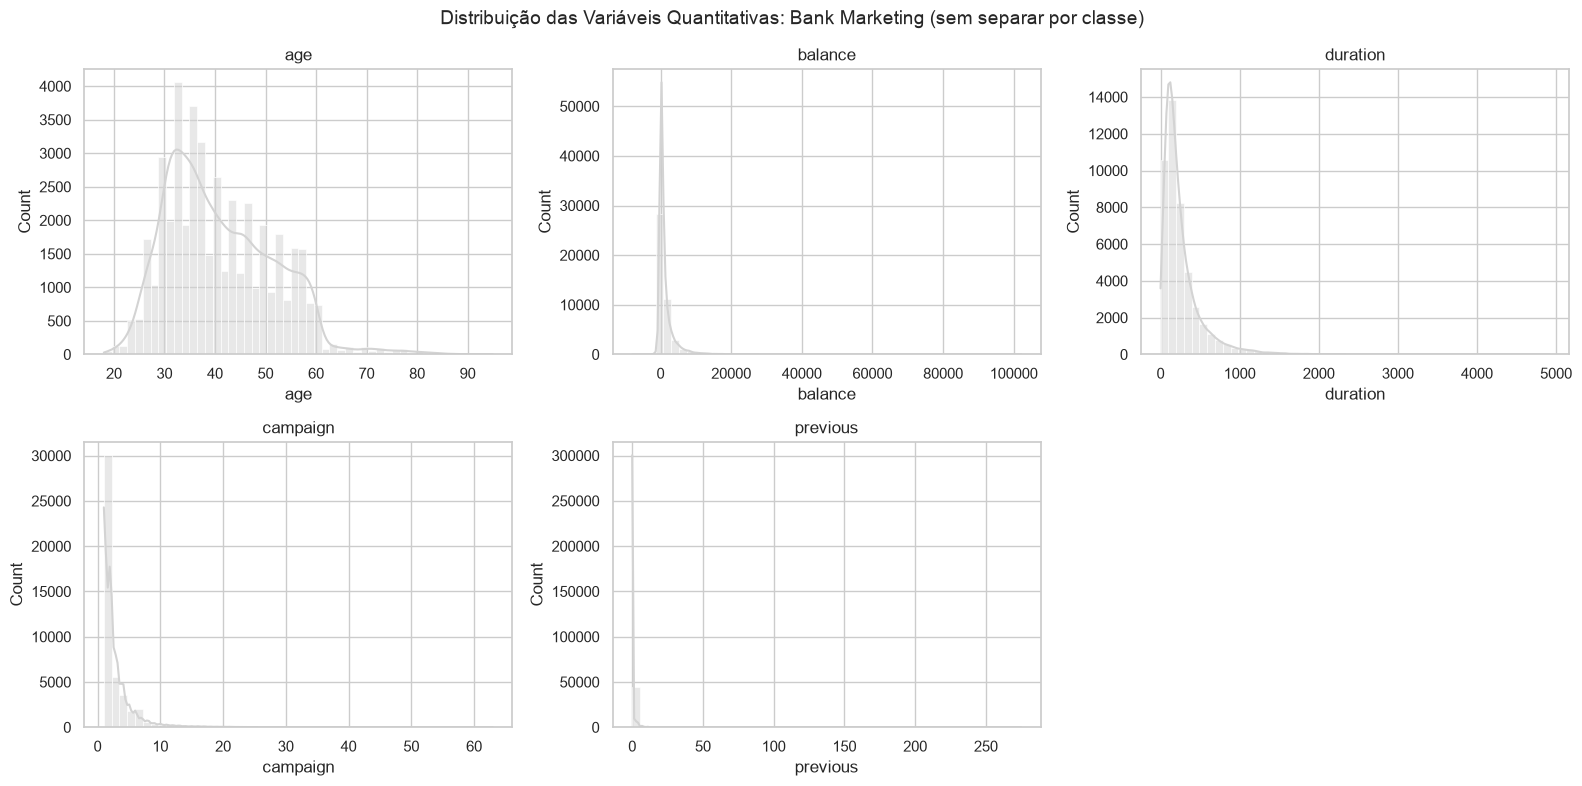

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, bins=50, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Bank Marketing (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

As caudas longas "achatam" os histogramas: quase todos os dados ficam espremidos nas primeiras barras. Para enxergar o formato da massa principal, repetimos os gráficos cortando no **percentil 99** (só para visualização — nenhum dado é removido aqui).

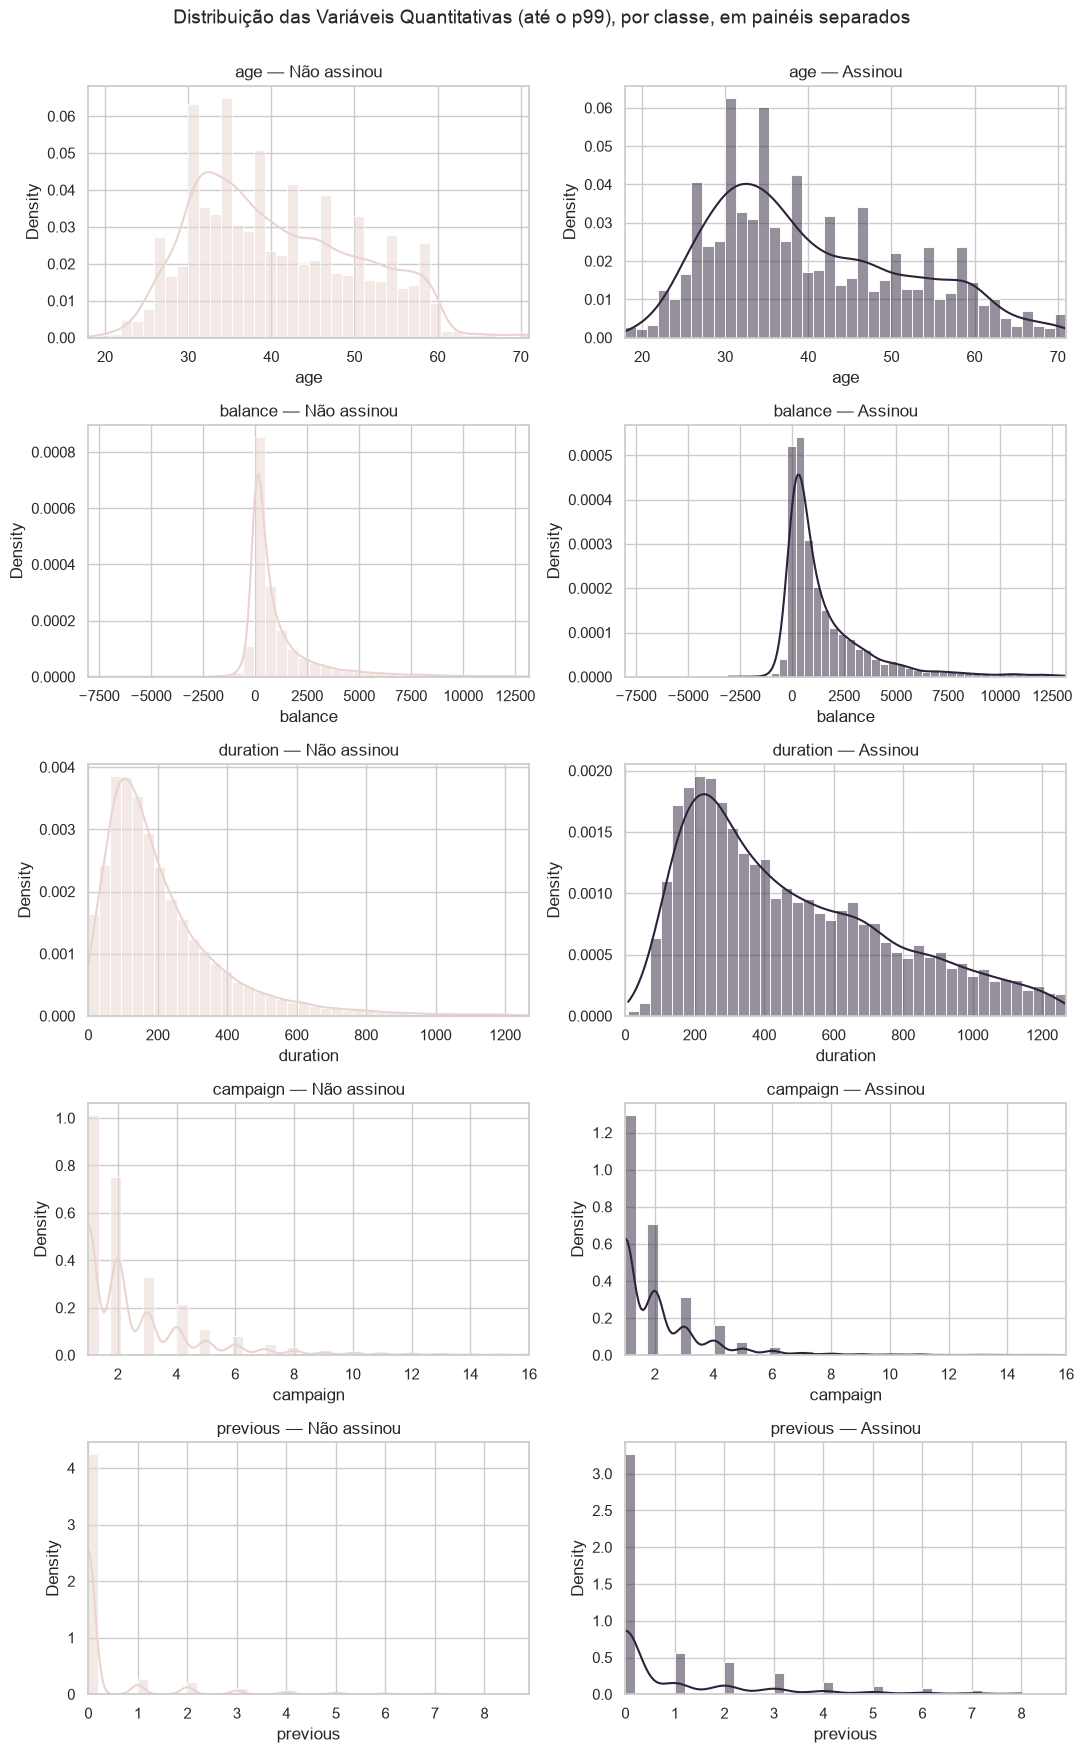

In [17]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(11, 3.5 * len(VARS_QUANT)))

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].quantile(0.99))
    for j, (classe, cor) in enumerate([("Não assinou", COR_CONTEXTO), ("Assinou", COR_DESTAQUE)]):
        subset = df[(df["assinou_deposito"] == classe) & df[col].between(*lim)]
        sns.histplot(data=subset, x=col, bins=40, kde=True, stat="density", color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas (até o p99), por classe, em painéis separados", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** alguma variável parece ter formato bem diferente entre "Não assinou" e "Assinou"?

*Resposta*: usamos `stat="density"` porque as classes têm tamanhos muito diferentes (~40 mil vs ~5 mil), então comparamos **formato**, não altura. A diferença mais gritante é em **`duration`**: quem assinou tem ligações bem mais longas (a massa se desloca para a direita). Em `age`, quem assinou tem uma distribuição mais "espalhada", com mais peso nos extremos (jovens e acima de 60). `campaign` é mais concentrada em 1–2 contatos para quem assinou, e `previous` tem mais valores > 0 entre os que assinaram.

**Atenção (domínio):** `duration` só é conhecida **depois** que a ligação termina — e uma ligação de 0 segundos implica "não assinou". Ela é ótima para *descrever* o que aconteceu, mas seria **vazamento de informação** (*data leakage*) num modelo que pretende prever quem vai assinar antes de ligar.

#### Testes de Aderência

*Será que o saldo médio anual (`balance`) segue uma distribuição normal?*

Usamos o **Shapiro-Wilk** com o **QQ-Plot** como apoio. Um detalhe importante: o `scipy` avisa que o p-valor do Shapiro-Wilk deixa de ser preciso para **N > 5.000**, e temos 45 mil linhas. Por isso aplicamos o teste numa **amostra aleatória de 5.000** linhas (e, como checagem, o teste de D'Agostino-Pearson em todos os dados).

Shapiro-Wilk (amostra n=5000) — balance: estatística=0.5148, p-valor=1.681e-79
Rejeita H0 (normalidade)? Sim (alpha = 0.05)
D'Agostino-Pearson (n=45211) — balance: estatística=64697.2, p-valor=0


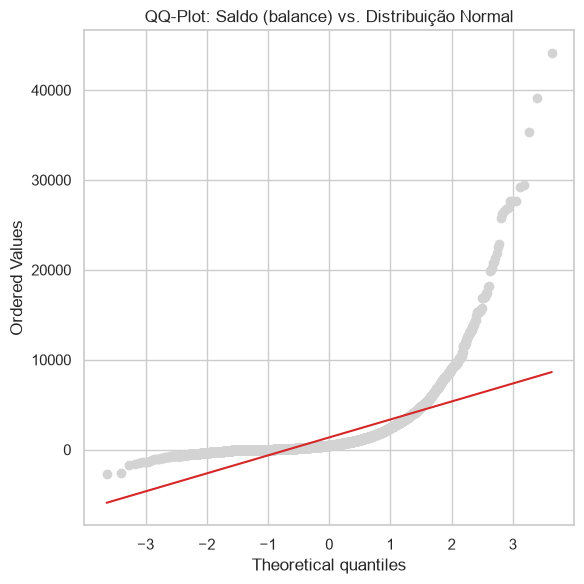

In [18]:
amostra_balance = df["balance"].sample(5000, random_state=SEED)

stat_sw, p_valor_sw = stats.shapiro(amostra_balance)
print(f"Shapiro-Wilk (amostra n=5000) — balance: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

stat_dp, p_valor_dp = stats.normaltest(df["balance"])
print(f"D'Agostino-Pearson (n={len(df)}) — balance: estatística={stat_dp:.1f}, p-valor={p_valor_dp:.4g}")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(amostra_balance, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Saldo (balance) vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** os pontos se afastam muito da reta vermelha na ponta direita (cauda muito mais pesada que a normal) — coerente com o Shapiro-Wilk rejeitando a normalidade com folga.

**Nota sobre o tamanho da amostra:** com dezenas de milhares de linhas, os testes de normalidade ficam sensíveis demais e rejeitam até desvios triviais. Aqui, porém, o desvio **não** é trivial: skewness ≈ 8, QQ-Plot com curva acentuada e o teste rejeitando mesmo numa amostra de 5.000. As três evidências concordam — temos evidência estatística **contra** a normalidade.

In [19]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].sample(5000, random_state=SEED))
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                               "p_valor": p, "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
age,0.9616,1.873981e-34,True
balance,0.5148,1.680636e-79,True
duration,0.7384,9.089163e-67,True
campaign,0.5904,6.766114e-76,True
previous,0.2855,4.649442e-88,True


Nenhuma variável quantitativa passa no teste de normalidade — nem `age`, que é a mais simétrica. Isso vai orientar a escolha de testes **não-paramétricos** (Spearman, Mann-Whitney, Kruskal-Wallis) na Seção 6.

**ECDF — outra forma de ver a distribuição**

A ECDF não depende de escolher o número de bins e é especialmente útil pra comparar dois grupos de tamanhos muito diferentes (como aqui). Vamos usar `duration`, a variável que mais pareceu separar as classes.

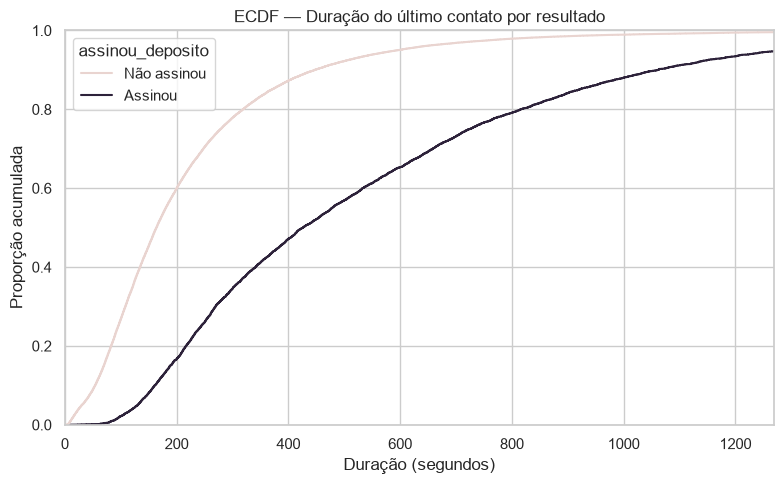

In [20]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="duration", hue="assinou_deposito",
             palette={"Não assinou": COR_CONTEXTO, "Assinou": COR_DESTAQUE})
plt.title("ECDF — Duração do último contato por resultado")
plt.xlabel("Duração (segundos)")
plt.ylabel("Proporção acumulada")
plt.xlim(0, df["duration"].quantile(0.99))
plt.tight_layout()
plt.show()

**Como ler:** a curva rosa sobe muito mais rápido — cerca de metade dos que **não** assinaram teve ligação de menos de ~3 minutos (mediana 164 s), enquanto para quem **assinou** a mediana é ~7 minutos (426 s). A maior distância vertical entre as curvas fica na faixa de 2 a 5 minutos.

### Métricas de Tendência Central

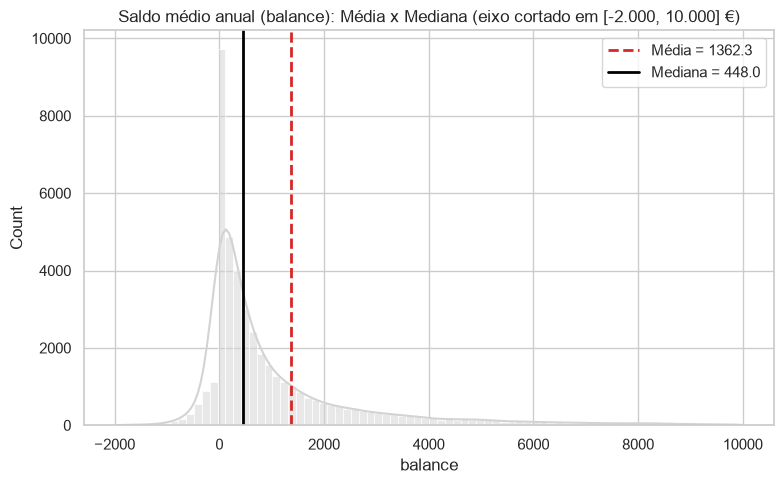

In [21]:
media_balance = df["balance"].mean()
mediana_balance = df["balance"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df[df["balance"].between(-2000, 10000)], x="balance", bins=80, kde=True, color=COR_NEUTRA)
plt.axvline(media_balance, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_balance:.1f}")
plt.axvline(mediana_balance, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_balance:.1f}")
plt.title("Saldo médio anual (balance): Média x Mediana (eixo cortado em [-2.000, 10.000] €)")
plt.legend()
plt.tight_layout()
plt.show()

A média (≈ 1.362 €) é **três vezes** a mediana (448 €): poucos clientes com saldos muito altos (até 102 mil €) puxam a média para a direita. Para descrever o "cliente típico", a mediana é a métrica adequada.

### Dispersão

In [22]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao["CV"] = df[VARS_QUANT].std() / df[VARS_QUANT].mean()  # coeficiente de variação
dispersao.round(2)

,var,std,IQR,CV
age,112.76,10.62,15.0,0.26
balance,9270598.95,3044.77,1356.0,2.24
duration,66320.57,257.53,216.0,1.00
campaign,9.60,3.10,2.0,1.12
previous,5.31,2.30,0.0,3.97


Note `previous` com **IQR = 0**: mais de 75% dos clientes nunca foram contatados antes, então todo valor > 0 vira "outlier" pela regra do IQR. Isso é uma limitação da regra para variáveis com excesso de zeros, e será discutido na Seção 4.

### Boxplot e violin plot por classe

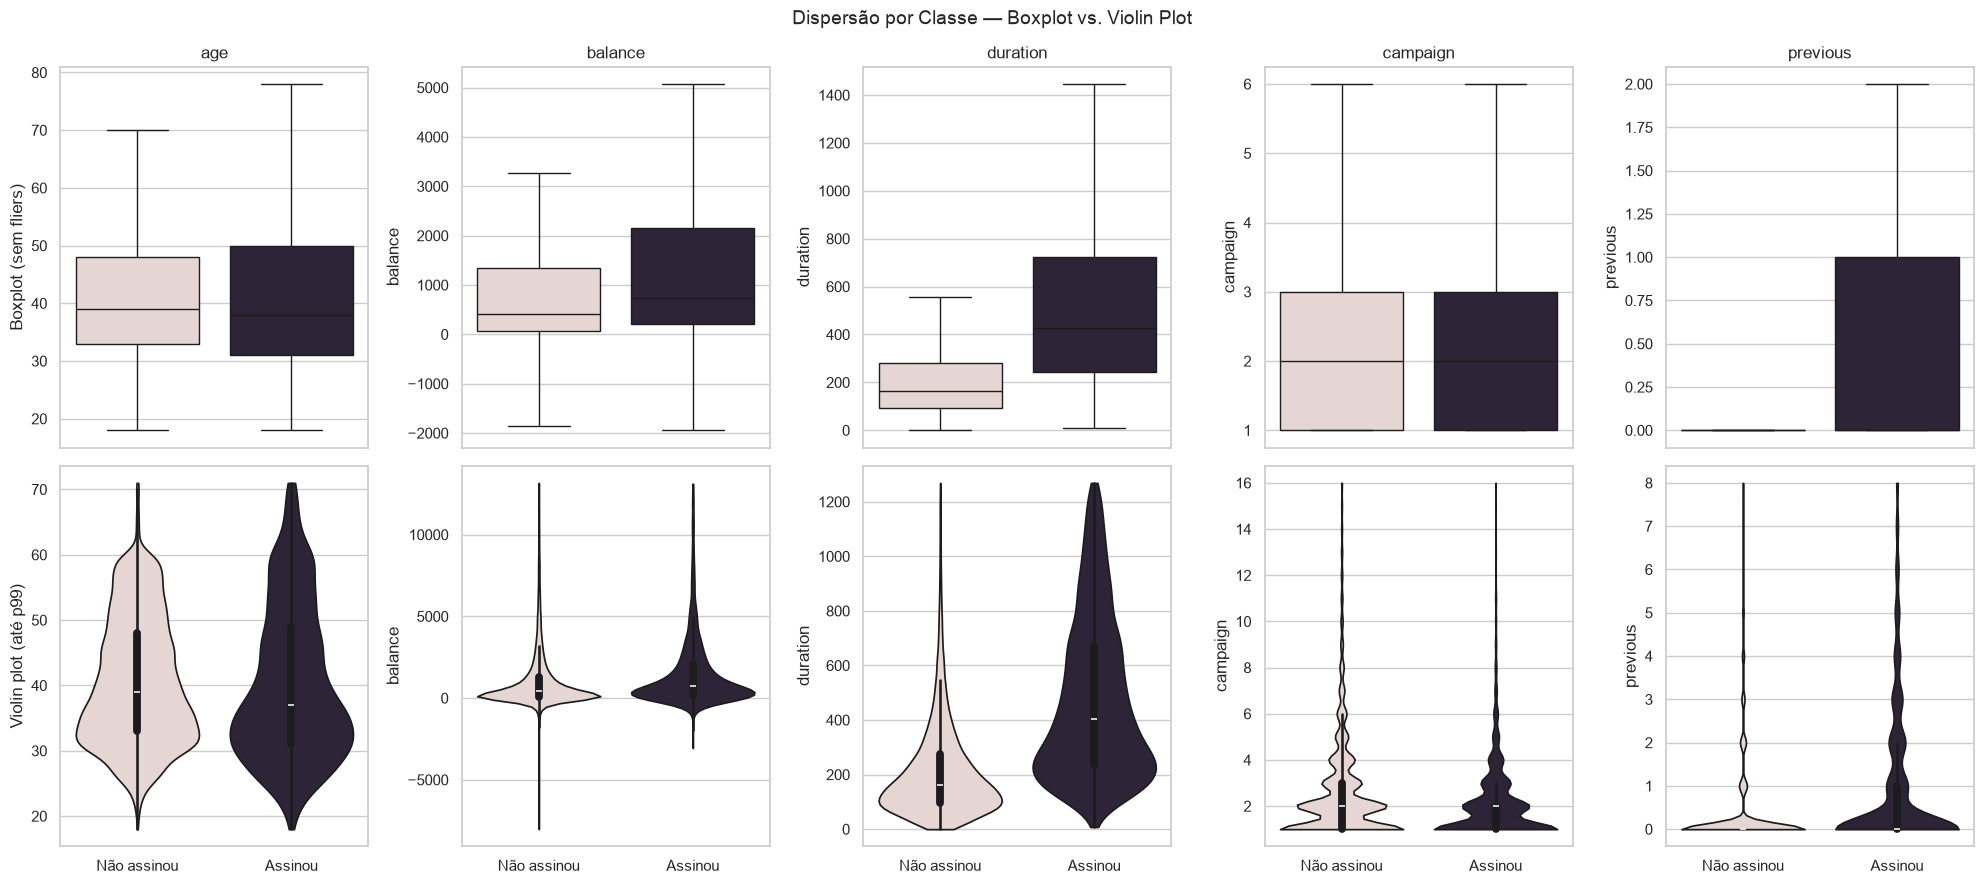

In [23]:
palette_classe = {"Não assinou": COR_CONTEXTO, "Assinou": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="assinou_deposito", y=col, hue="assinou_deposito",
                palette=palette_classe, legend=False, showfliers=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    dados_p99 = df[df[col] <= df[col].quantile(0.99)]
    sns.violinplot(data=dados_p99, x="assinou_deposito", y=col, hue="assinou_deposito",
                   palette=palette_classe, legend=False, cut=0, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot (sem fliers)")
axes[1, 0].set_ylabel("Violin plot (até p99)")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre as classes?

*Resposta*: escondemos os *fliers* no boxplot e cortamos o violin no p99 porque, com 45 mil linhas, os outliers dominariam o gráfico. **`duration`** é, de longe, a que mais separa: a caixa de "Assinou" fica quase inteira acima da mediana de "Não assinou". `balance` também é um pouco maior entre quem assinou (mediana 733 € vs 417 €). `campaign` é ligeiramente menor entre quem assinou — insistir com muitas ligações não parece aumentar a conversão. `age` tem medianas parecidas, mas "Assinou" tem uma caixa mais larga.

## 4. Tratamento de Dados Ausentes e Outliers

Com o retrato estatístico "antes" (Seção 3) e o diagnóstico dos mecanismos de ausência (Seção 2), decidimos como tratar os ausentes e os outliers. Depois do tratamento, rodamos a estatística descritiva de novo ("depois") para confirmar o efeito das escolhas.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [24]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
        "pct_outliers": round(n_outliers / len(df) * 100, 2),
        "maximo": df[col].max(),
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers,pct_outliers,maximo
age,10.5,70.5,487.0,1.08,95.0
balance,-1962.0,3462.0,4729.0,10.46,102127.0
duration,-221.0,643.0,3235.0,7.16,4918.0
campaign,-2.0,6.0,3064.0,6.78,63.0
previous,0.0,0.0,8257.0,18.26,275.0


### Visualizando os Outliers

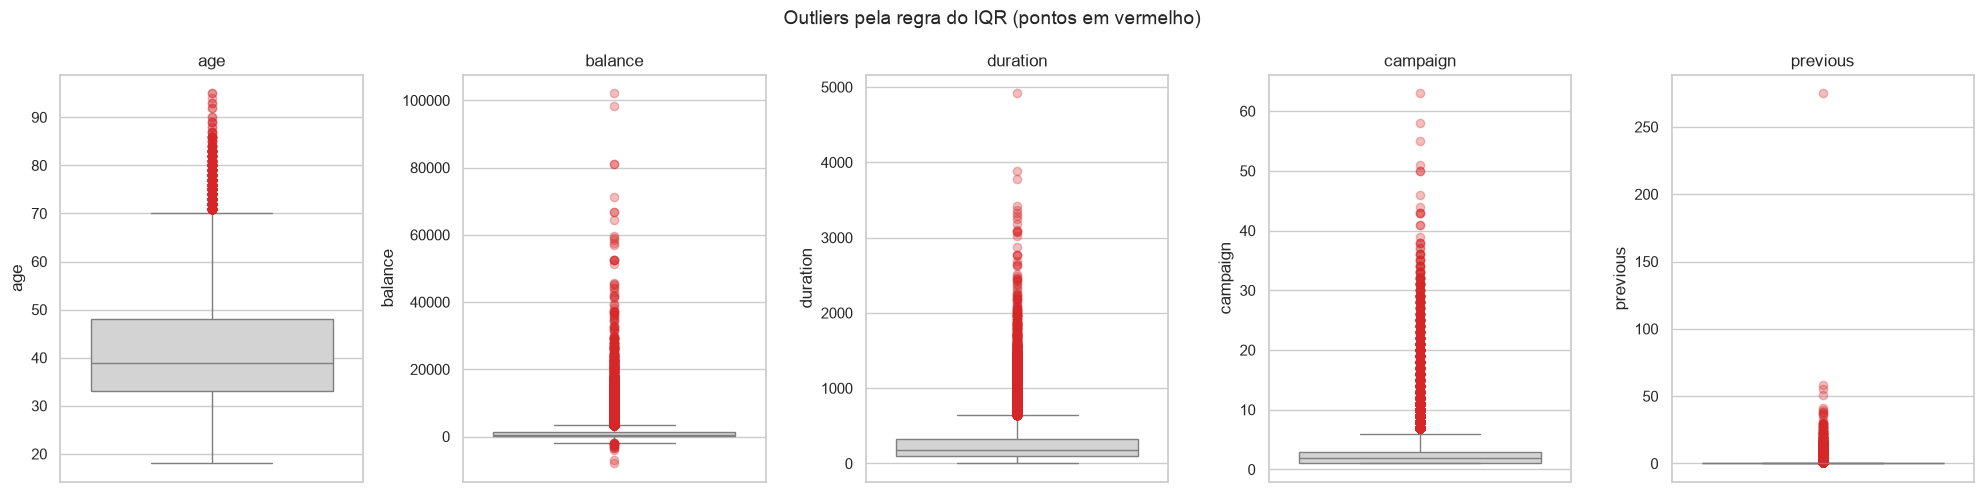

In [25]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o", alpha=0.3),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

In [26]:
# Olhando os valores mais extremos de cada variável
pd.DataFrame({col: df[col].nlargest(6).values for col in VARS_QUANT}, index=[f"top{i}" for i in range(1, 7)])

,age,balance,duration,campaign,previous
top1,95,102127,4918,63,275
top2,95,98417,3881,58,58
top3,94,81204,3785,55,55
top4,93,81204,3422,51,51
top5,93,71188,3366,50,41
top6,92,66721,3322,50,40


**Pra discutir:** classificando os outliers pela tabela da aula 9:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

*Resposta*:
- **`age`** (outliers acima de ~70 anos): **estatístico**. Clientes idosos existem e, como veremos, convertem bem mais.
- **`balance`** (≈ 10% de outliers, de −8 mil a 102 mil €): **estatístico**. Saldos negativos (cheque especial) e saldos altos são plausíveis num banco.
- **`duration`** (até 4.918 s ≈ 82 min): **estatístico**. Ligações longas são raras mas possíveis, e são exatamente as que mais convertem. Há 3 ligações com 0 segundos (ligação não completada) — plausível.
- **`campaign`** (até 63 contatos na mesma campanha): **de domínio** — muito acima do razoável para uma campanha, mas a sequência de máximos (44, 46, 50, 50, 51, 55, 58, 63) é contínua, sem um salto que indique erro de digitação. Mantemos, mas sinalizamos.
- **`previous`**: a regra do IQR marca **todo valor > 0** (IQR = 0), o que não faz sentido — o problema é a regra, não os dados. O único ponto realmente suspeito é o **máximo = 275**, quando o segundo maior é 58: um salto de quase 5x, isolado. É muito provavelmente um **erro de dados**.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o diagnóstico da Seção 2, cada coluna recebe um tratamento diferente:

| Coluna | Mecanismo provável | Volume | Tratamento |
|---|---|---|---|
| `job`, `education` | MCAR | ~4,5% das linhas (somadas) | **Remover** as linhas — risco de viés baixo, perda pequena |
| `contact` | MAR (depende do período) | 28,8% | **Manter** como categoria `"desconhecido"` — remover enviesaria (perderíamos maio/junho, de baixa conversão) |
| `poutcome` | Estrutural ("não se aplica") | 81,7% | **Manter** como categoria `"sem_contato_previo"` |
| `pdays = -1` | Estrutural (sentinela) | 81,7% | Converter `-1` em `NaN` e criar a flag `contato_previo` |

In [27]:
linhas_antes = df.shape[0]
df_antes = df.copy()

# job/education: MCAR e poucos -> remover linhas
df = df.dropna(subset=["job", "education"]).reset_index(drop=True)

# contact: MAR -> categoria explícita
df["contact"] = df["contact"].fillna("desconhecido")

# poutcome: estruturalmente ausente -> categoria explícita
df["poutcome"] = df["poutcome"].fillna("sem_contato_previo")

# pdays: sentinela -1 -> flag + NaN (para não distorcer estatísticas)
df["contato_previo"] = np.where(df["pdays"] == -1, "Não", "Sim")
df["pdays"] = df["pdays"].replace(-1, np.nan)

linhas_depois = df.shape[0]
print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois} "
      f"({(linhas_antes - linhas_depois) / linhas_antes:.1%})")
print("\nAusentes restantes:")
print(df.isna().sum()[df.isna().sum() > 0])

Linhas antes: 45211 | Linhas depois: 43193 | Removidas: 2018 (4.5%)

Ausentes restantes:
pdays    35281
dtype: int64


O único `NaN` restante é o de `pdays`, que agora significa explicitamente "não se aplica" (cliente nunca contatado). Para quem **foi** contatado antes, `pdays` passa a ter uma distribuição interpretável:

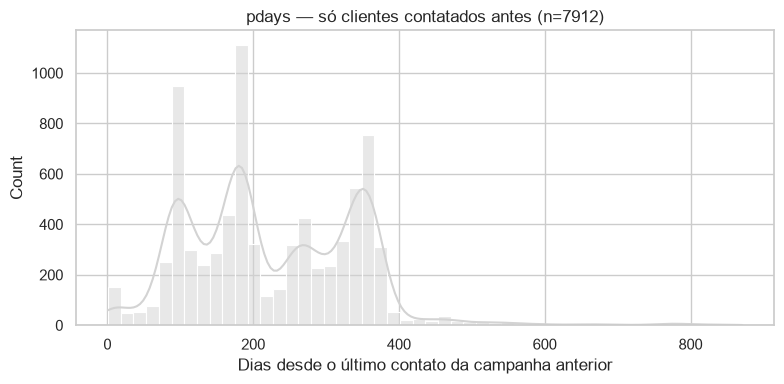

count    7912.0
mean      225.0
std       115.4
min         1.0
25%       133.0
50%       195.0
75%       328.0
max       871.0
Name: pdays, dtype: float64


In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["pdays"].dropna(), bins=50, kde=True, color=COR_NEUTRA, ax=ax)
ax.set_title(f"pdays — só clientes contatados antes (n={df['pdays'].notna().sum()})")
ax.set_xlabel("Dias desde o último contato da campanha anterior")
plt.tight_layout()
plt.show()
print(df["pdays"].describe().round(1))

### Decidindo o Tratamento dos Outliers

Como nos dados de aula, **não vamos remover automaticamente**. A maioria dos outliers é **estatística** (valores raros, mas reais e informativos) e será **mantida**. A exceção é o registro com `previous = 275`: um valor isolado, ~5x maior que o segundo maior, classificado como **erro de dados**. Como não temos como corrigir, removemos essa única linha (último recurso, impacto de 1 em ~43 mil).

In [29]:
print(df.loc[df["previous"] == df["previous"].max(), ["age", "job", "campaign", "pdays", "previous", "poutcome"]])

linhas_antes_outlier = df.shape[0]
df = df[df["previous"] < 275].reset_index(drop=True)
print(f"\nLinhas removidas por erro de dados: {linhas_antes_outlier - df.shape[0]}")

       age         job  campaign  pdays  previous poutcome
27895   40  management         2  262.0       275    other

Linhas removidas por erro de dados: 1


Mantemos os demais valores originais, mas ilustramos como ficaria uma transformação logarítmica em `duration` — útil se, mais adiante, a assimetria atrapalhar algum teste ou modelo. (Para `balance` o `log` não serve diretamente, porque há valores negativos.)

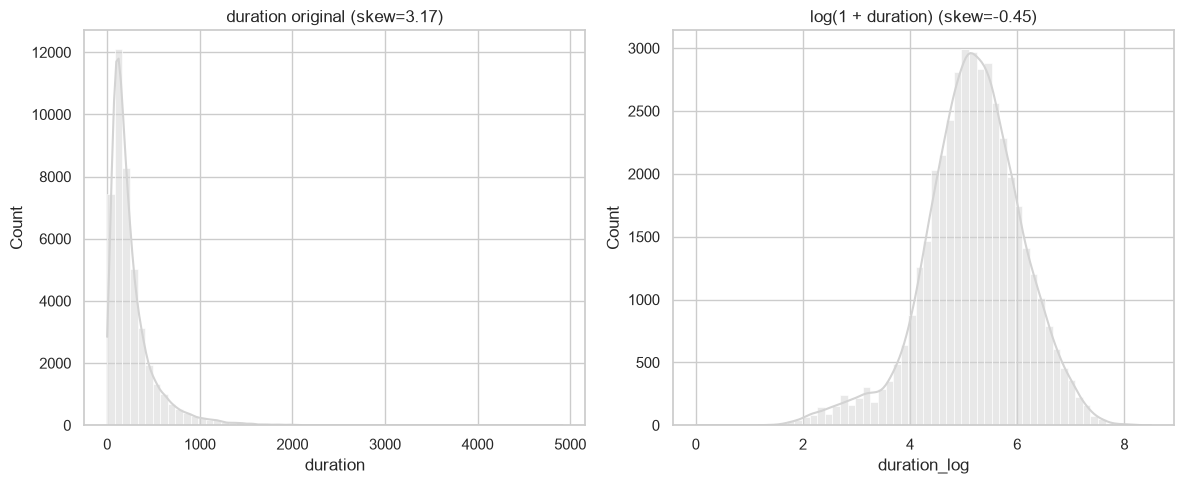

In [30]:
df["duration_log"] = np.log1p(df["duration"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="duration", bins=60, kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"duration original (skew={df['duration'].skew():.2f})")

sns.histplot(data=df, x="duration_log", bins=60, kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + duration) (skew={df['duration_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria?

*Resposta*: sim — `duration` passa de uma distribuição com cauda longa (skew ≈ 3) para algo bem mais simétrico, próximo de um sino (com uma leve cauda à esquerda causada pelas ligações muito curtas). Mantemos `duration_log` como coluna auxiliar, mas as próximas seções usam a variável original.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter quase todos os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar com o "antes".

In [31]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
age,40.76,39.00,10.51,18.00,95.00,0.70,0.31
balance,1354.05,442.00,3042.14,-8019.00,102127.00,8.40,142.31
duration,258.32,180.00,258.16,0.00,4918.00,3.17,18.47
campaign,2.76,2.00,3.06,1.00,58.00,4.79,36.95
previous,0.58,0.00,1.92,0.00,58.00,7.85,111.20


### Comparando "antes" x "depois"

In [32]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
age,0.685,0.698,0.320,0.313,0.013,-0.007
balance,8.360,8.400,140.752,142.314,0.040,1.563
duration,3.144,3.170,18.154,18.469,0.026,0.316
campaign,4.899,4.792,39.250,36.946,-0.106,-2.304
previous,41.846,7.853,4506.861,111.199,-33.993,-4395.662


**Pra discutir:** os valores mudaram muito?

*Resposta*: para `age`, `balance`, `duration` e `campaign` a mudança é mínima — removemos ~4,5% das linhas, e de forma (provavelmente) aleatória, então o formato das distribuições se mantém. A grande exceção é **`previous`**: a remoção de **um único ponto** (o 275) derrubou a skewness e, principalmente, a kurtosis em ordens de grandeza. É um ótimo exemplo de como a curtose é sensível a um único valor extremo — e uma confirmação de que aquele ponto distorcia a variável inteira.

**O saldo (`balance`) ainda rejeita normalidade?**

Mesmo Shapiro-Wilk da Seção 3 (amostra de 5.000), agora nos dados tratados.

In [33]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["balance"].sample(5000, random_state=SEED))
print(f"Shapiro-Wilk (antes)  — balance: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — balance: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — balance: estatística=0.5148, p-valor=1.681e-79
Shapiro-Wilk (depois) — balance: estatística=0.5531, p-valor=9.688e-78


**Visualizando antes x depois, lado a lado**

Sobrepomos as distribuições de `balance` e `previous` (as que mais chamaram atenção na Seção 4), comparando `df_antes` com o `df` tratado. Usamos escala log no eixo Y em `previous` para enxergar a cauda.

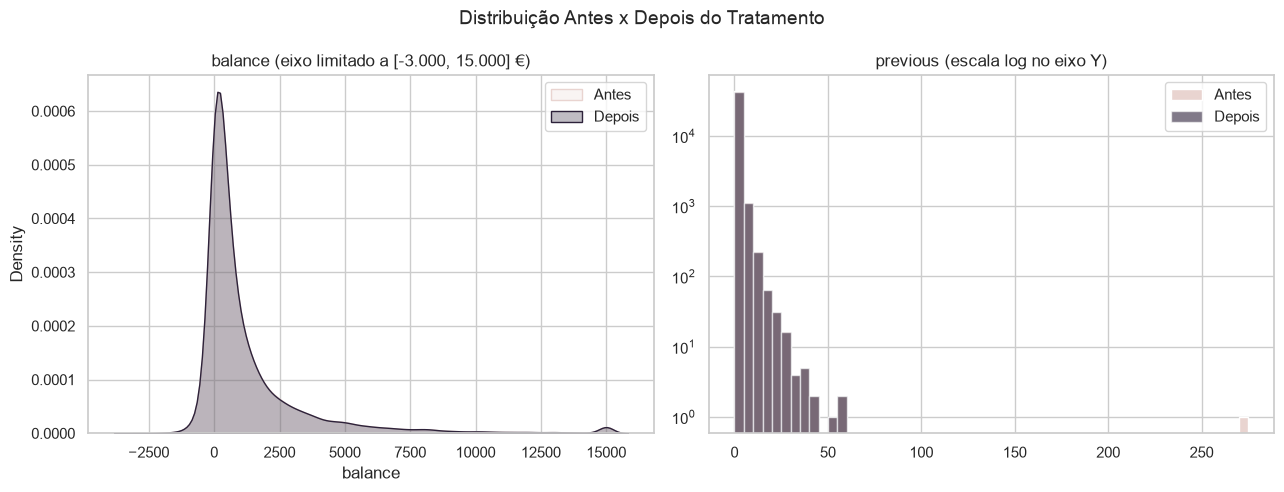

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

lim_balance = (-3000, 15000)
sns.kdeplot(df_antes["balance"].clip(*lim_balance), color=COR_CONTEXTO, fill=True, label="Antes", ax=axes[0])
sns.kdeplot(df["balance"].clip(*lim_balance), color=COR_DESTAQUE, fill=True, alpha=0.3, label="Depois", ax=axes[0])
axes[0].set_title("balance (eixo limitado a [-3.000, 15.000] €)")
axes[0].legend()

bins = np.arange(0, 280, 5)
axes[1].hist(df_antes["previous"], bins=bins, color=COR_CONTEXTO, label="Antes")
axes[1].hist(df["previous"], bins=bins, color=COR_DESTAQUE, alpha=0.6, label="Depois")
axes[1].set_yscale("log")
axes[1].set_title("previous (escala log no eixo Y)")
axes[1].legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" se sobrepõem?

*Resposta*: em `balance`, praticamente sim — o tratamento foi conservador. Em `previous`, a única diferença visível é o ponto isolado em 275, que sumiu. Essa checagem confirma que o tratamento teve exatamente o efeito pretendido (corrigir um erro pontual) sem deformar o resto da distribuição.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Avaliação de frequência e desbalanceamento das variáveis qualitativas.

#### Frequências absolutas e relativas

In [35]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- job ---
               absoluta  relativa
job                              
blue-collar        9278     0.215
management         9215     0.213
technician         7355     0.170
admin.             5000     0.116
services           4004     0.093
retired            2145     0.050
self-employed      1540     0.036
entrepreneur       1411     0.033
unemployed         1274     0.029
housemaid          1195     0.028
student             775     0.018

--- marital ---
          absoluta  relativa
marital                     
married      25945     0.601
single       12219     0.283
divorced      5028     0.116

--- education ---
           absoluta  relativa
education                    
secondary     23131     0.536
tertiary      13261     0.307
primary        6800     0.157

--- default ---
         absoluta  relativa
default                    
no          42410     0.982
yes           782     0.018

--- housing ---
         absoluta  relativa
housing                    
yes         

#### Visualizando as frequências

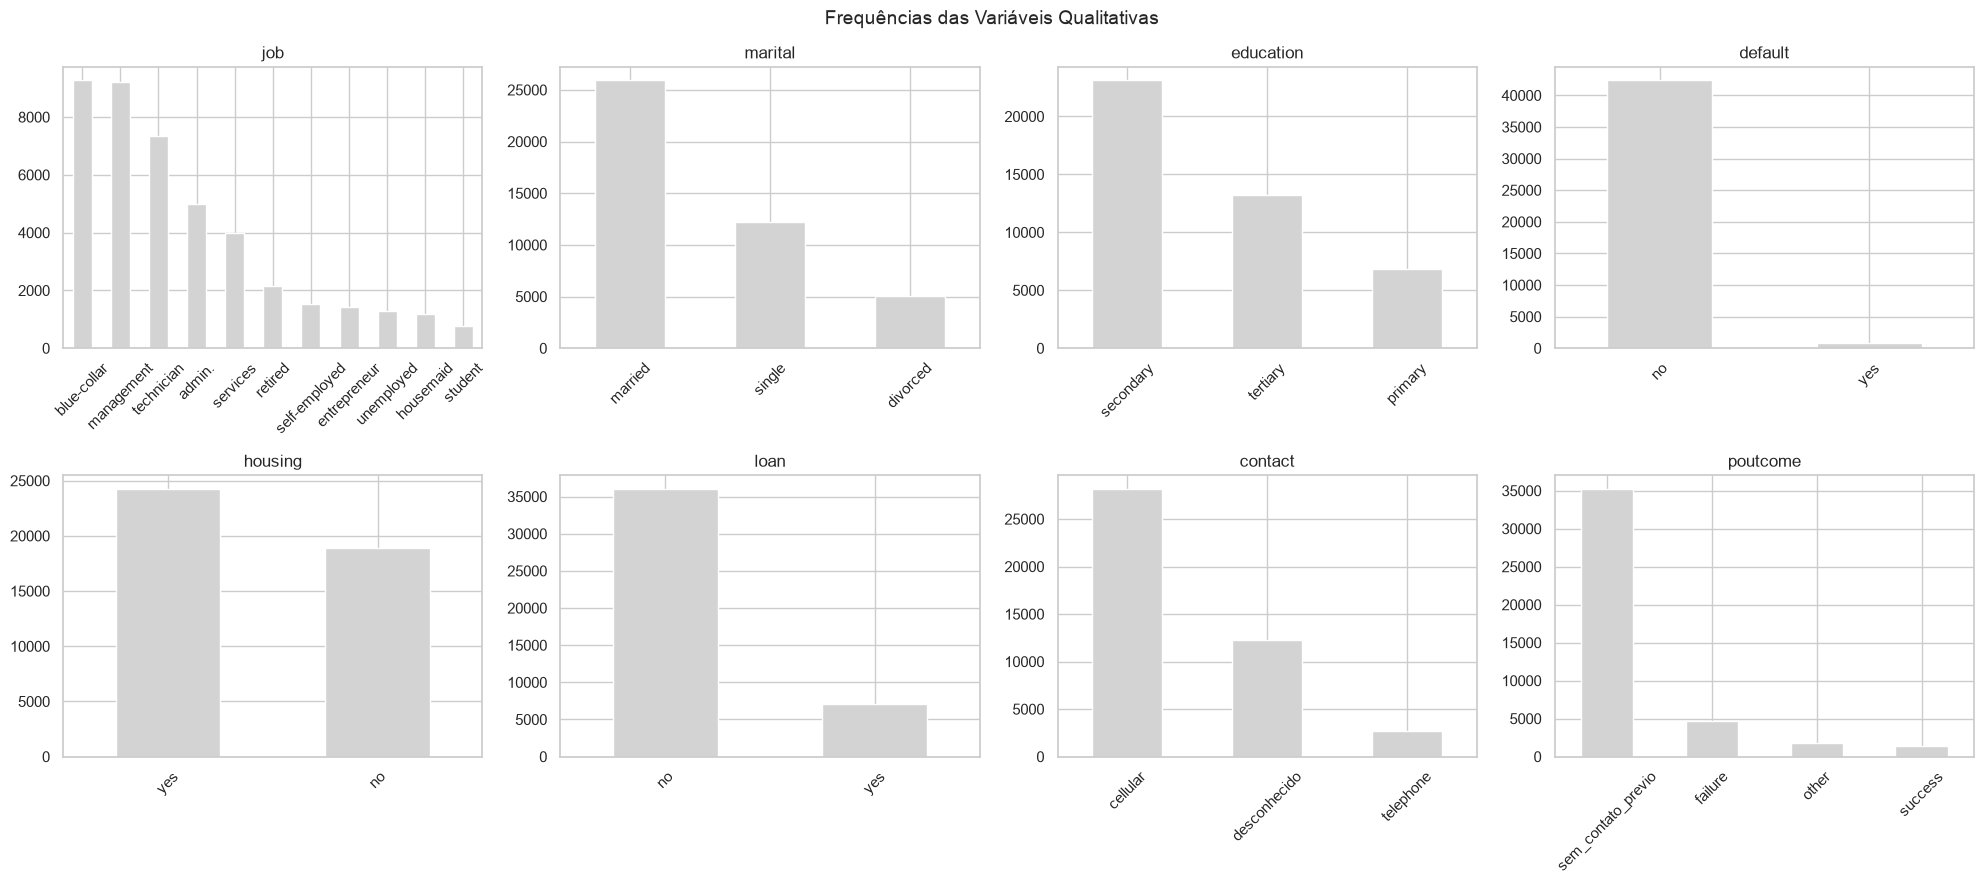

In [36]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=45)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

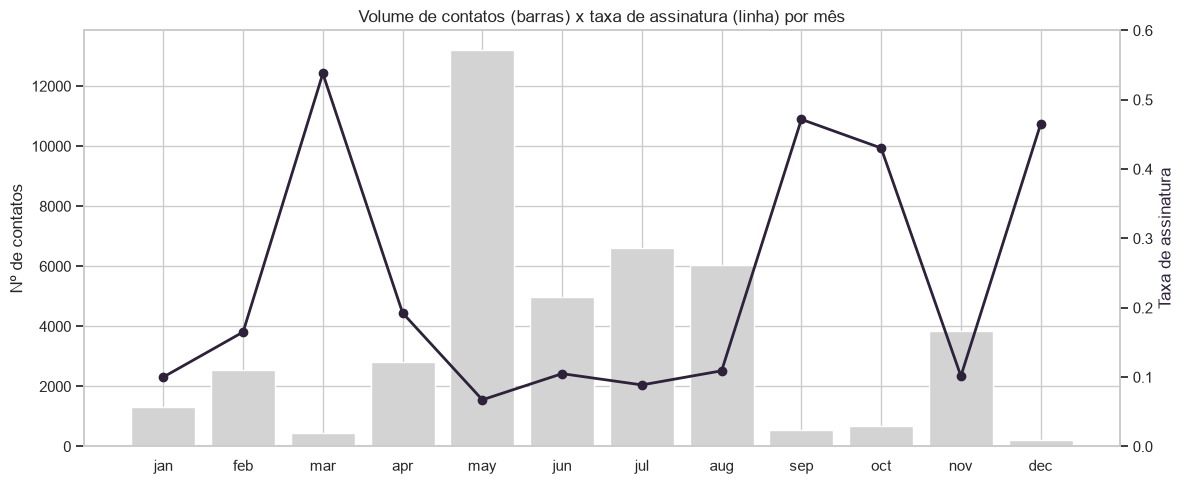

In [37]:
# Aspecto temporal: volume de contatos e taxa de assinatura por mês
por_mes = df.groupby("month").agg(
    contatos=("assinou_deposito", "size"),
    taxa_assinou=("assinou_deposito", lambda s: (s == "Assinou").mean()),
).reindex(ordem_meses)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(por_mes.index, por_mes["contatos"], color=COR_NEUTRA)
ax1.set_ylabel("Nº de contatos")
ax2 = ax1.twinx()
ax2.plot(por_mes.index, por_mes["taxa_assinou"], color=COR_DESTAQUE, marker="o", linewidth=2)
ax2.set_ylabel("Taxa de assinatura", color=COR_DESTAQUE)
ax2.set_ylim(0, 0.6)
ax2.grid(False)
ax1.set_title("Volume de contatos (barras) x taxa de assinatura (linha) por mês")
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada?

*Resposta*: sim, várias. `default` é a mais extrema (~98% "no"), seguida de `poutcome` (~82% "sem_contato_previo") e `loan` (~84% "no"). `job` tem 11 categorias, com `blue-collar` e `management` dominando. No aspecto temporal, há um contraste forte: **maio** concentra quase 1/3 dos contatos mas tem uma das **menores** taxas de assinatura, enquanto **mar, set, out e dez** têm poucos contatos e taxas acima de 40%. Cruzamentos com categorias raras (ex.: `default = yes`, `poutcome = success`) terão poucos casos e devem ser interpretados com cautela.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Aplicamos as duas em todas as qualitativas, incluindo o alvo `assinou_deposito`.

In [38]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["assinou_deposito"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
job,11.0,11.97,0.870
marital,3.0,5.16,0.832
education,3.0,3.40,0.899
default,2.0,54.23,0.131
housing,2.0,1.29,0.989
loan,2.0,5.08,0.645
contact,3.0,10.47,0.736
poutcome,4.0,24.78,0.469
assinou_deposito,2.0,7.60,0.518


**Pra discutir:** alguma variável está com entropia bem próxima de 0? E o próprio alvo?

*Resposta*: `default` tem a menor entropia (≈ 0,13) e razão ≈ 54:1 — quase não carrega informação. O **alvo `assinou_deposito` é bem desbalanceado**: razão ≈ 7,6:1 (só ~11,7% assinaram) e entropia ≈ 0,5. Isso precisa ser levado em conta: na análise, comparamos **proporções/densidades** em vez de contagens; num modelo futuro, a acurácia seria uma métrica enganosa (prever sempre "Não assinou" já acertaria ~88%) e seria preciso usar métricas como precisão/recall/F1 ou AUC, e talvez técnicas de balanceamento.

### Análise Bivariada

Agora avaliamos como as variáveis se relacionam entre si e com o alvo `assinou_deposito`.

#### Quantitativa x Quantitativa - Correlação

* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como nenhuma variável passou no Shapiro-Wilk e há muitos outliers, **Spearman** é a escolha mais segura, mas calculamos as três para comparar.

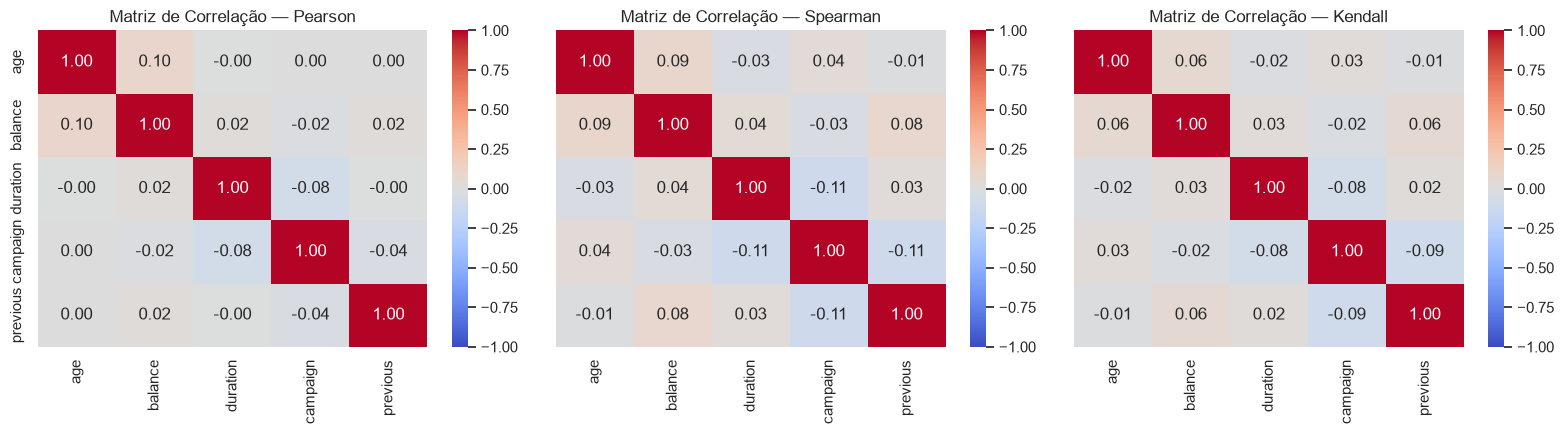

In [39]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

Como a matriz é simétrica, podemos plotar só o triângulo inferior:

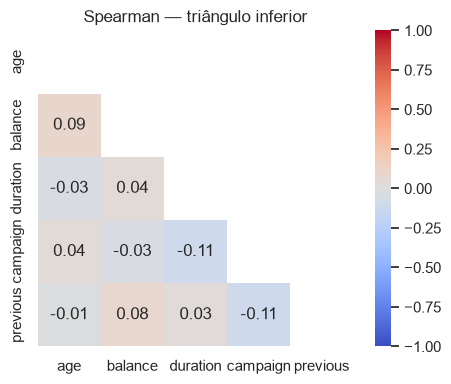

In [40]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(5, 4))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1)
plt.grid(False)
plt.title("Spearman — triângulo inferior")
plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par?

*Resposta*: todas as correlações são **fracas** (|r| < 0,15) — as variáveis quantitativas são praticamente independentes entre si. As maiores divergências aparecem em pares com `campaign` e `previous` (ex.: `campaign` x `previous`: Pearson ≈ −0,04 vs Spearman ≈ −0,11; `balance` x `previous`: 0,02 vs 0,08): essas variáveis têm excesso de zeros/uns e caudas extremas, e o Pearson é "puxado" pelos outliers, enquanto o Spearman, baseado em postos, captura melhor a tendência monotônica fraca. O par mais "forte" é `age` x `balance` (≈ 0,10).

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `balance` por motivo de domínio (o patrimônio tende a crescer ao longo da vida) e porque é o par com a maior |correlação| na tabela. Com 43 mil pontos, usamos uma **amostra de 5.000** e `alpha` baixo para evitar *overplotting*, e escala *symlog* no eixo Y por causa dos saldos negativos e extremos.

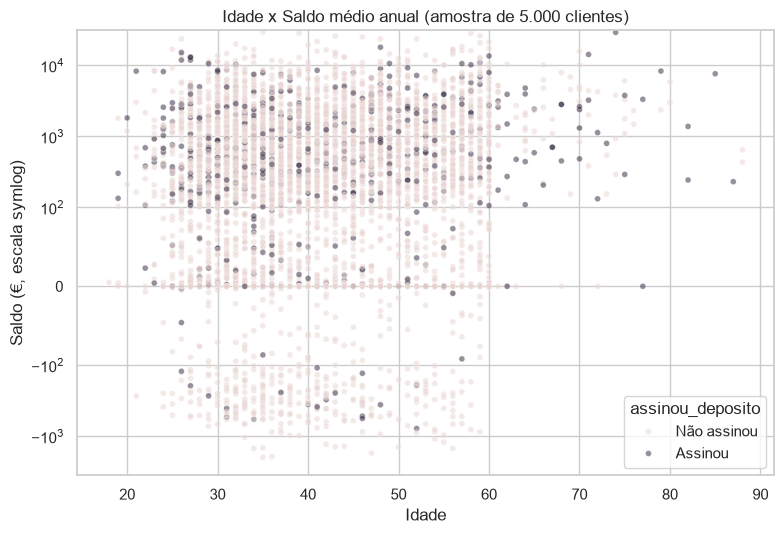

In [41]:
amostra = df.sample(5000, random_state=SEED)

plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=amostra, x="age", y="balance", hue="assinou_deposito",
                palette=palette_classe, alpha=0.5, s=18)
plt.yscale("symlog", linthresh=100)
plt.title("Idade x Saldo médio anual (amostra de 5.000 clientes)")
plt.xlabel("Idade")
plt.ylabel("Saldo (€, escala symlog)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível? As classes ocupam regiões diferentes?

*Resposta*: a tendência é muito fraca (nuvem quase sem inclinação), coerente com ρ ≈ 0,10. O que chama atenção são as **faixas de idade**: a densidade de pontos roxos ("Assinou") aumenta claramente depois dos 60 anos e abaixo dos ~25, enquanto a faixa de 30–55 é dominada por "Não assinou". As classes não se separam pelo saldo.

#### Quantitativa x Qualitativa: Comparando Grupos

Como nenhuma quantitativa é normal, os testes que devemos reportar são os **não-paramétricos**: **Mann-Whitney U** (2 grupos) e **Kruskal-Wallis** (3+ grupos). Calculamos também os paramétricos (T-Test de Welch e ANOVA) como contraste.

Com dezenas de milhares de linhas, quase qualquer diferença vira "significativa". Por isso acrescentamos um **tamanho de efeito**: a correlação rank-biserial (r = 1 − 2U/(n₁n₂)), que vai de −1 a 1 e diz *quanto* os grupos diferem, não só *se* diferem.

In [42]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_nao = df.loc[df["assinou_deposito"] == "Não assinou", col]
    grupo_sim = df.loc[df["assinou_deposito"] == "Assinou", col]

    stat_t, p_t = stats.ttest_ind(grupo_nao, grupo_sim, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_nao, grupo_sim)                 # não-paramétrico
    rank_biserial = 1 - 2 * stat_u / (len(grupo_nao) * len(grupo_sim))      # tamanho de efeito

    resultados_comparacao.append({
        "variavel": col,
        "mediana_nao_assinou": grupo_nao.median(),
        "mediana_assinou": grupo_sim.median(),
        "p_valor_ttest": p_t,
        "p_valor_mannwhitney": p_u,
        "concordam": (p_t < 0.05) == (p_u < 0.05),
        "efeito_rank_biserial": round(rank_biserial, 3),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,mediana_nao_assinou,mediana_assinou,p_valor_ttest,p_valor_mannwhitney,concordam,efeito_rank_biserial
variavel,,,,,,
age,39.0,38.0,3.113504e-05,5.086102e-02,False,-0.017
balance,413.0,718.0,3.673977e-21,4.218257e-92,True,0.176
duration,164.0,431.0,0.000000e+00,0.000000e+00,True,0.617
campaign,2.0,2.0,3.788531e-103,2.269550e-67,True,-0.144
previous,0.0,0.0,1.889563e-70,2.826975e-262,True,0.202


**Pra discutir:** os dois testes concordam?

*Resposta*: em 4 das 5 variáveis, sim — ambos significativos (com n ≈ 43 mil, o poder dos testes é enorme). A exceção é **`age`**: o T-Test acusa diferença (p ≈ 3e-5), mas o Mann-Whitney não (p ≈ 0,051). O T-Test compara **médias**, que são puxadas pelas caudas (mais idosos entre quem assinou), enquanto as **medianas** são quase iguais (39 vs 38). Como os dados não são normais, reportamos o **Mann-Whitney**: não há evidência de que a idade *típica* difira entre as classes — o efeito da idade aparece nos extremos, como veremos na análise de fairness. O que realmente diferencia as variáveis é o **tamanho do efeito**: `duration` tem efeito grande (r ≈ 0,62), enquanto `balance`, `campaign` e `previous` têm efeitos pequenos (|r| entre 0,14 e 0,20) e `age` é praticamente nulo (r ≈ −0,02) — mesmo com p-valores minúsculos. Significância estatística ≠ relevância prática.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`education` tem 3 categorias (primary, secondary, tertiary). Testamos se o saldo (`balance`) difere entre os níveis de escolaridade.

ANOVA          — balance entre níveis de education: estatística=171.435, p-valor=6.9298e-75
Kruskal-Wallis — balance entre níveis de education: estatística=356.315, p-valor=4.2384e-78
education
primary      402.5
secondary    392.0
tertiary     577.0
Name: balance, dtype: float64


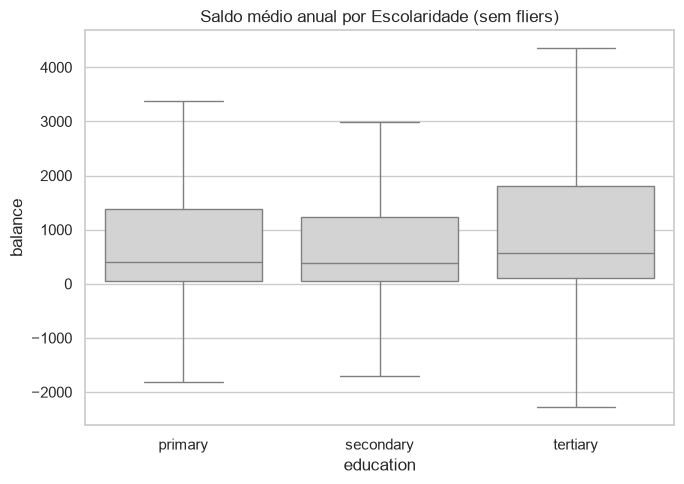

In [43]:
ordem_educ = ["primary", "secondary", "tertiary"]
grupos_educ = [df.loc[df["education"] == nivel, "balance"].values for nivel in ordem_educ]

stat_anova, p_anova = stats.f_oneway(*grupos_educ)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_educ)          # não-paramétrico

print(f"ANOVA          — balance entre níveis de education: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — balance entre níveis de education: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")
print(df.groupby("education")["balance"].median())

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="education", y="balance", order=ordem_educ, color=COR_NEUTRA, showfliers=False)
plt.title("Saldo médio anual por Escolaridade (sem fliers)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA?

*Resposta*: ambos indicam diferença significativa entre pelo menos um nível de escolaridade. Como `balance` não é normal e tem outliers extremos (que inflam a variância e afetam a ANOVA), o **Kruskal-Wallis** é o resultado a reportar. Pelas medianas e pelo boxplot, a diferença está concentrada no nível **`tertiary`** (mediana ≈ 577 €), enquanto `primary` e `secondary` são parecidos (≈ 400 €) — não é um crescimento gradual. E as caixas se sobrepõem bastante: o efeito existe, porém é modesto.

#### Qualitativa x Qualitativa

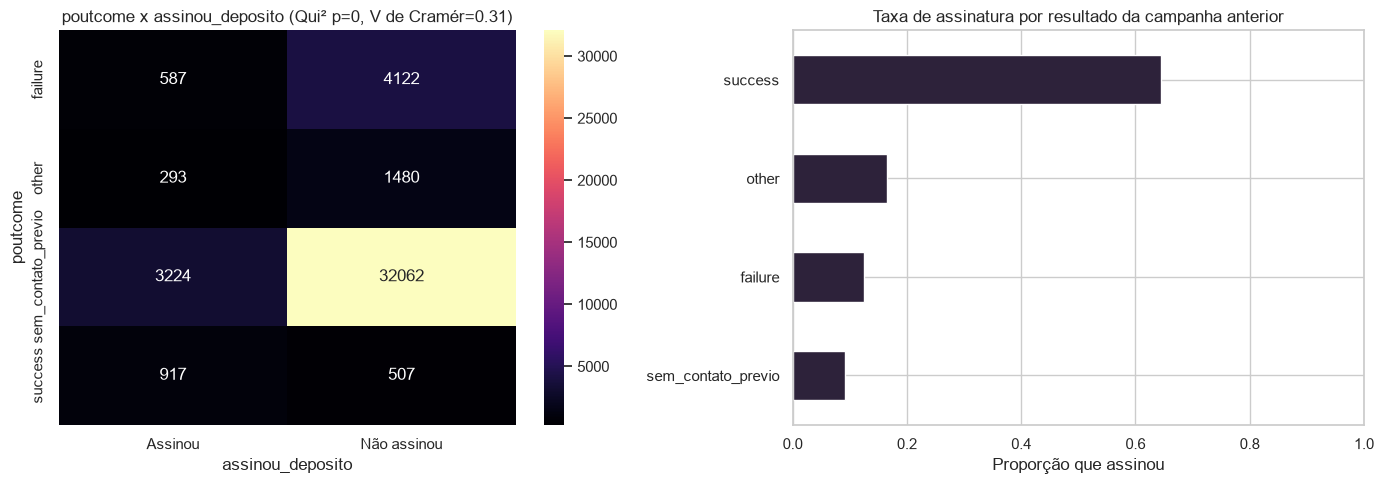

In [44]:
contingencia_poutcome = pd.crosstab(df["poutcome"], df["assinou_deposito"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_poutcome)

# V de Cramér: tamanho de efeito para o Qui-Quadrado (0 = sem associação, 1 = associação perfeita)
v_cramer = np.sqrt(chi2 / (contingencia_poutcome.values.sum() * (min(contingencia_poutcome.shape) - 1)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(contingencia_poutcome, annot=True, fmt="d", cmap="magma", ax=axes[0])
axes[0].set_title(f"poutcome x assinou_deposito (Qui² p={p_chi2:.3g}, V de Cramér={v_cramer:.2f})")

pd.crosstab(df["poutcome"], df["assinou_deposito"], normalize="index")["Assinou"].sort_values().plot(
    kind="barh", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Taxa de assinatura por resultado da campanha anterior")
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Proporção que assinou")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Pra discutir:** `poutcome` e `assinou_deposito` são independentes?

*Resposta*: não. O Qui-Quadrado rejeita a independência e o V de Cramér indica uma associação de magnitude moderada (bem acima das demais variáveis cadastrais). O padrão é muito claro: clientes cuja campanha anterior foi um **sucesso** assinam em **~65%** dos casos, contra ~9% dos que nunca foram contatados. Quem já disse "sim" uma vez tende a dizer de novo — um insight direto para priorizar a lista de ligações.

In [45]:
# Panorama: associação de cada qualitativa com o alvo (Qui² + V de Cramér)
associacoes = []
for col in VARS_QUALI + ["month", "contato_previo"]:
    tab = pd.crosstab(df[col], df["assinou_deposito"])
    chi2_c, p_c, _, _ = stats.chi2_contingency(tab)
    associacoes.append({"variavel": col, "p_valor": p_c,
                        "v_cramer": np.sqrt(chi2_c / (tab.values.sum() * (min(tab.shape) - 1)))})

pd.DataFrame(associacoes).set_index("variavel").sort_values("v_cramer", ascending=False).round(4)

,p_valor,v_cramer
variavel,,
poutcome,0.0,0.3087
month,0.0,0.2602
contato_previo,0.0,0.1641
contact,0.0,0.1479
housing,0.0,0.1382
job,0.0,0.1337
education,0.0,0.0735
loan,0.0,0.0687
marital,0.0,0.0666


Todas dão p-valor ≈ 0 (de novo, efeito do n grande), então é o V de Cramér que ordena a importância. As mais associadas à assinatura são `poutcome` (≈ 0,31) e `month` (≈ 0,26), seguidas de `contato_previo` e `contact` (≈ 0,15) — todas ligadas a **quando/como** o contato aconteceu e ao histórico. Entre as de perfil, só `housing` e `job` passam de 0,1; `education`, `loan`, `marital` e `default` têm associação fraca.

#### Avaliação de Fairness

Será que o desfecho se comporta igual em diferentes subgrupos de **atributos sensíveis**? Este dataset não tem sexo, mas tem **idade** e **estado civil** — dois atributos protegidos em várias legislações de crédito e não-discriminação. Se um modelo de priorização de ligações fosse treinado com esses dados, ele poderia aprender a favorecer ou excluir faixas etárias.

In [46]:
df["faixa_etaria"] = pd.cut(df["age"], bins=[0, 30, 40, 50, 60, 100], right=False,
                            labels=["<30", "30-39", "40-49", "50-59", "60+"])

print("Desbalanceamento — estado civil:")
print(metrica_desbalanceamento(df["marital"]))
print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — estado civil:
n_classes                 3.000
razao_desbalanceamento    5.160
entropia_normalizada      0.832
dtype: float64

Desbalanceamento — faixa etária:
n_classes                  5.000
razao_desbalanceamento    10.860
entropia_normalizada       0.869
dtype: float64


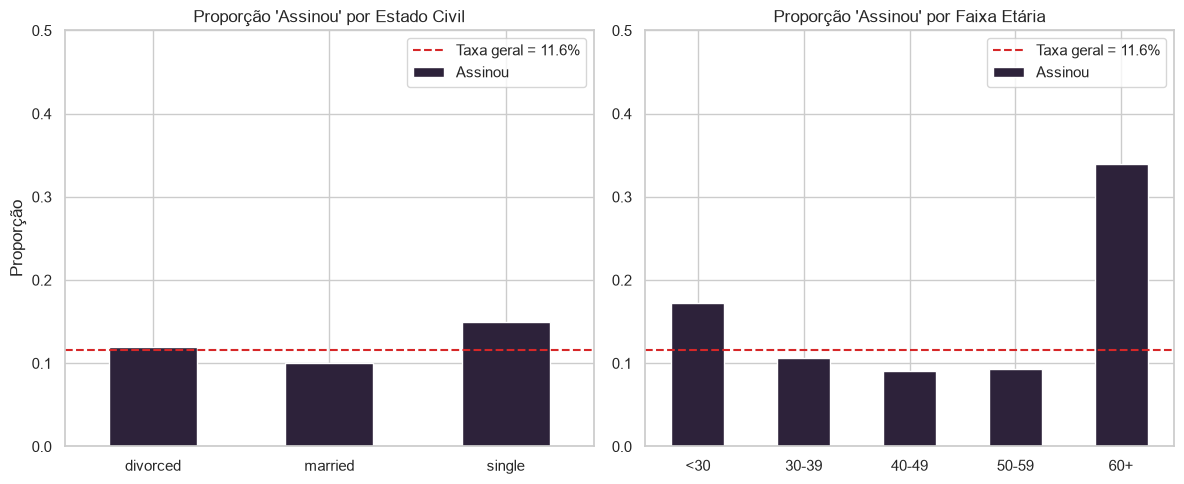

In [47]:
prop_por_civil = pd.crosstab(df["marital"], df["assinou_deposito"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["assinou_deposito"], normalize="index").round(3)
taxa_geral = (df["assinou_deposito"] == "Assinou").mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_civil["Assinou"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Assinou' por Estado Civil")
axes[0].set_ylabel("Proporção")

prop_por_faixa["Assinou"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Assinou' por Faixa Etária")

for ax in axes:
    ax.axhline(taxa_geral, color=COR_ALERTA, linestyle="--", label=f"Taxa geral = {taxa_geral:.1%}")
    ax.set_ylim(0, 0.5)
    ax.tick_params(axis="x", rotation=0)
    ax.set_xlabel("")
    ax.legend()

plt.tight_layout()
plt.show()

**Pra discutir:** a taxa de assinatura varia entre estado civil ou faixa etária?

*Resposta*: varia pouco por estado civil (solteiros ~15%, casados ~10%), mas **muito** por idade: a faixa **60+** assina em ~1/3 dos casos (≈ 3x a taxa geral) e a faixa **<30** também fica acima da média, desenhando um "U". Isso tem explicações de domínio plausíveis (aposentados com mais liquidez e aversão a risco preferem depósitos a prazo; jovens/estudantes iniciando a vida financeira). Mas atenção: a faixa 60+ é **pequena** (poucos % da base) — o banco ligou pouco para quem converte mais. Um modelo treinado nesses dados poderia reproduzir uma decisão operacional passada, e não necessariamente uma preferência real dos clientes.

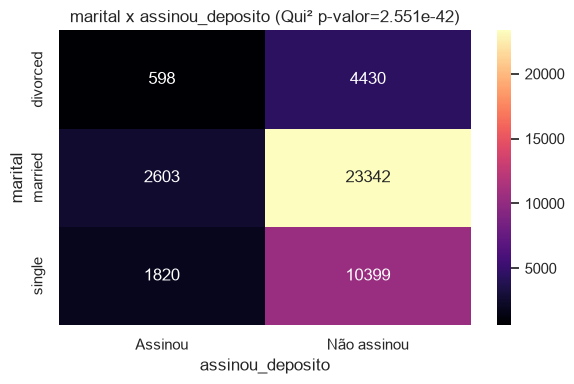

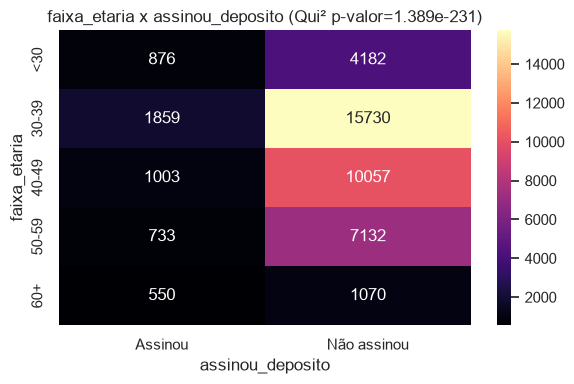

In [48]:
for atributo in ["marital", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["assinou_deposito"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x assinou_deposito (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação?

*Resposta*: sim, para os dois atributos (p-valores muito pequenos). Mas, como na aula, o teste aponta **que** existe associação, não **por quê**. Pode ser um efeito real (perfil financeiro de aposentados), um viés de seleção (quem o banco escolheu para ligar, e em qual mês) ou uma mistura dos dois. Antes de qualquer uso desses dados para decidir quem recebe ofertas, essa disparidade precisa ser investigada.

#### Outliers bivariados

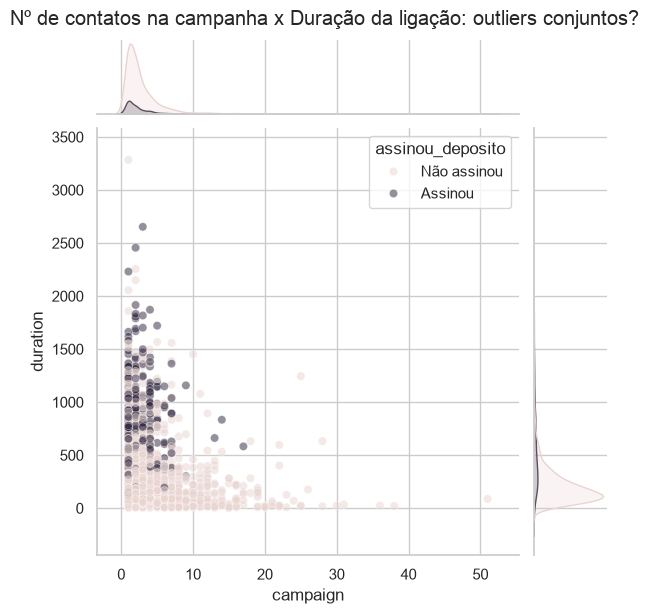

In [49]:
amostra_joint = df.sample(5000, random_state=SEED)
g = sns.jointplot(data=amostra_joint, x="campaign", y="duration", hue="assinou_deposito",
                  palette=palette_classe, alpha=0.5, height=6)
g.figure.suptitle("Nº de contatos na campanha x Duração da ligação: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos univariados, mas que se destaca aqui?

*Resposta*: sim. Isoladamente, ligações de ~15–20 minutos e clientes com ~10–15 contatos não são tão raros. Mas a **combinação** "muitos contatos **e** ligação longa" quase não existe: quando o banco insiste muito, as ligações tendem a ser curtas (o cliente desliga). Os poucos pontos nessa região são anomalias bivariadas que valeria inspecionar. Também se vê que quase todos os "Assinou" estão em `campaign` baixo e `duration` alto.

#### Análise Multivariada

##### Matriz de Correlação

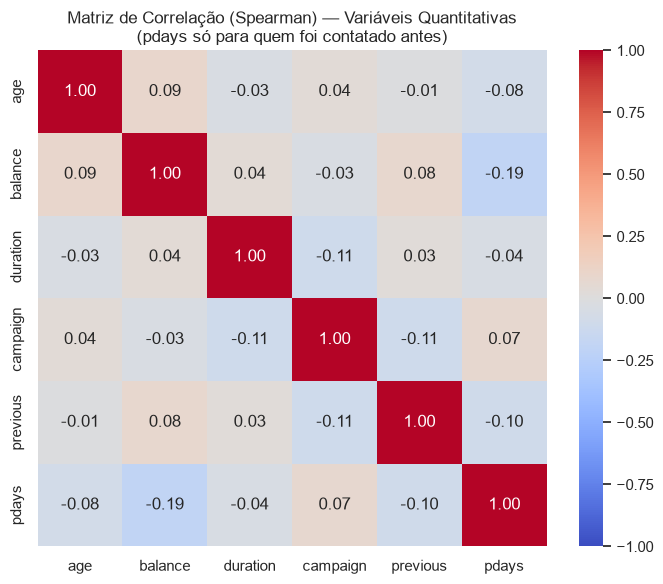

In [50]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT + ["pdays"]].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas\n(pdays só para quem foi contatado antes)")
plt.tight_layout()
plt.show()

**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Nenhuma correlação forte: não há redundância entre as quantitativas, cada uma traz informação própria. Incluímos `pdays` (calculado só nas linhas em que existe, já que o `NaN` é ignorado par a par) — ela também se correlaciona pouco com as demais.

##### Correlograma

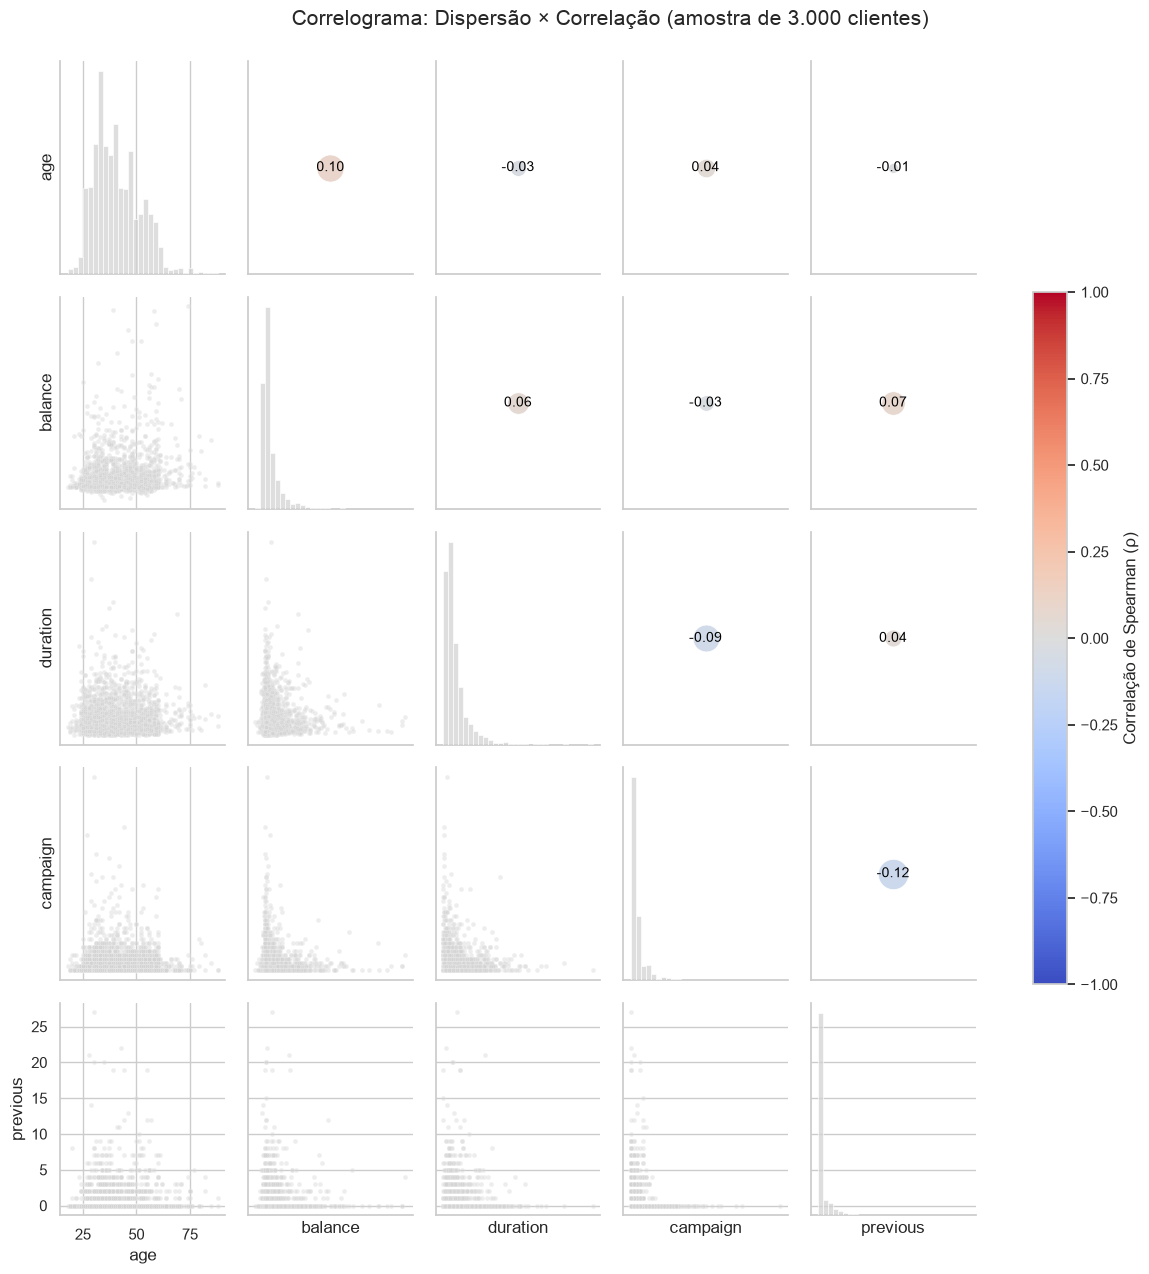

In [51]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y).statistic
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap="coolwarm", vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

amostra_corr = df[VARS_QUANT].sample(3000, random_state=SEED)

g = sns.PairGrid(amostra_corr, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.4, s=12)
g.map_diag(sns.histplot, color=COR_NEUTRA, bins=30)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada
sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.figure.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman (ρ)")

g.figure.suptitle("Correlograma: Dispersão × Correlação (amostra de 3.000 clientes)", y=1.02, fontsize=15)
plt.show()

Usamos Spearman nos círculos (coerente com a não-normalidade) e uma amostra de 3.000 linhas para o gráfico ficar legível. Os círculos pequenos confirmam: as quantitativas são quase independentes entre si — o poder explicativo para a assinatura parece vir mais de **variáveis isoladas** (`duration`, `poutcome`, idade, mês) do que de combinações lineares entre elas.

## Síntese

### Principais conclusões

1. **Ausentes disfarçados e com mecanismos diferentes.** O dataset parece "limpo" (`isna()` zerado), mas tem ausentes codificados como `"unknown"` e o sentinela `pdays = -1`. Cada coluna pediu um tratamento: `job`/`education` (MCAR, ~4,5%) foram removidas; `contact` (MAR, concentrado em mai–jun/2008) virou categoria, pois removê-la enviesaria a taxa de conversão; `poutcome`/`pdays` são estruturalmente ausentes ("nunca contatado") e viraram categoria/flag.
2. **Distribuições muito assimétricas e outliers majoritariamente legítimos.** Nenhuma quantitativa é normal; `balance`, `duration`, `campaign` e `previous` têm caudas longas. Só um ponto foi tratado como erro de dados (`previous = 275`) — e removê-lo derrubou a curtose de `previous` em ordens de grandeza.
3. **Alvo desbalanceado (~11,7% assinaram).** Comparações devem usar proporções/densidades, e um modelo futuro não deve ser avaliado por acurácia.
4. **O que mais se associa à assinatura é o contexto do contato, não o perfil cadastral.** `duration` tem o maior efeito (mas é *data leakage* para predição), seguida de `poutcome = success` (~65% de conversão), mês do contato e tipo de contato. Insistir com muitas ligações (`campaign` alto) não aumenta a conversão.
5. **Disparidade por idade (fairness).** Clientes 60+ convertem ~3x mais que a média, mas são pouco contatados; a taxa por idade forma um "U". Isso pode ser preferência real ou viés operacional, e precisa ser investigado antes de usar os dados para decidir quem recebe ofertas.

### Declaração de Uso de IA

| Ferramenta | Para o que foi aplicada | O que foi aceito / modificado / rejeitado e por quê |
|---|---|---|
| Claude Code (Anthropic) | Adaptar a estrutura do notebook da aula (`arquivo-eda-original.ipynb`) ao dataset Bank Marketing: código das seções, escolha das variáveis, diagnóstico dos `"unknown"` e rascunho das respostas às perguntas de discussão. | *A preencher pelo aluno:* revisar cada decisão (ex.: remover `job`/`education`, manter `contact` como categoria, remover `previous = 275`) e registrar aqui o que foi aceito, modificado ou rejeitado, e por quê. |

## Exportando o dataset tratado

Exporta o `df` tratado para `data/clean/dataset.csv`, que é o arquivo lido pelo `app.py` (via `src/data_loader.py`).

In [52]:
df.to_csv(RAIZ / "data" / "clean" / "dataset.csv", index=False)
print(f"Exportado: {df.shape[0]} linhas x {df.shape[1]} colunas -> data/clean/dataset.csv")

Exportado: 43192 linhas x 20 colunas -> data/clean/dataset.csv
